In [ ]:
# Import required libraries

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

RANDOM_STATE = 42
N_BOOTSTRAPS = 5

np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# Load the Employee Attrition dataset

DATA_PATH = "WA_Fn-UseC_-HR-Employee-Attrition.csv"

if not os.path.exists(DATA_PATH):
    possible_files = glob.glob("**/*Employee*Attrition*.csv", recursive=True)

    if possible_files:
        DATA_PATH = possible_files[0]
    else:
        raise FileNotFoundError(
            "Dataset not found. Place the IBM HR Analytics CSV "
            "in the notebook folder or update DATA_PATH."
        )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nAttrition distribution:")
print(df["Attrition"].value_counts())

Dataset loaded successfully.
Dataset shape: (1470, 35)

First five rows:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2



Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Attrition distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [ ]:
# Prepare X and y, then split the dataset

if "Attrition" not in df.columns:
    raise ValueError("The dataset must contain an 'Attrition' column.")

df = df.drop_duplicates().reset_index(drop=True)

# Remove columns that are identifiers or contain no useful variation
columns_to_drop = [
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours"
]

X = df.drop(
    columns=["Attrition"] + columns_to_drop,
    errors="ignore"
).copy()

y = df["Attrition"].map({
    "No": 0,
    "Yes": 1
})

if y.isna().any():
    raise ValueError(
        "Unexpected values found in Attrition. "
        "Check df['Attrition'].value_counts()."
    )

y = y.astype(int)

# First: 60% training and 40% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=RANDOM_STATE,
    stratify=y
)

# Second: divide the temporary data equally into validation and test
X_validation, X_test, y_validation, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_validation.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTarget mapping: No = 0, Yes = 1")

Training set: (882, 30)
Validation set: (294, 30)
Testing set: (294, 30)

Training target distribution:
Attrition
0    740
1    142
Name: count, dtype: int64

Target mapping: No = 0, Yes = 1


In [ ]:
# Identify numeric and categorical columns

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Number of numeric features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)


# Numeric preprocessing: replace missing values with the median
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing: replace missing values and encode categories
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each feature type
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("\nPreprocessing pipeline created successfully.")

Number of numeric features: 23
Number of categorical features: 7

Numeric features:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical features:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Preprocessing pipeline created successfully.


In [ ]:
# Create five bootstrap samples from scratch

n_train = len(X_train)
training_positions = np.arange(n_train)

bootstrap_samples = []
bootstrap_indices = []
oob_indices = []

for sample_number in range(N_BOOTSTRAPS):

    # Draw N positions with replacement
    sampled_positions = np.random.choice(
        training_positions,
        size=n_train,
        replace=True
    )

    # Store the complete bootstrap sample, including repeated records
    bootstrap_indices.append(sampled_positions)

    # Identify unique positions selected at least once
    unique_positions = np.unique(sampled_positions)

    # OOB positions are those never selected
    out_of_bag_positions = np.setdiff1d(
        training_positions,
        unique_positions
    )

    # Store the bootstrap feature and target data
    X_bootstrap = X_train.iloc[sampled_positions].copy()
    y_bootstrap = y_train.iloc[sampled_positions].copy()

    bootstrap_samples.append((X_bootstrap, y_bootstrap))
    oob_indices.append(out_of_bag_positions)

    unique_percentage = len(unique_positions) / n_train * 100
    oob_percentage = len(out_of_bag_positions) / n_train * 100

    print(f"\nBootstrap Sample {sample_number + 1}")
    print("Total sampled records:", len(sampled_positions))
    print("Unique records:", len(unique_positions))
    print("Repeated selections:", n_train - len(unique_positions))
    print("OOB records:", len(out_of_bag_positions))
    print(f"Unique percentage: {unique_percentage:.2f}%")
    print(f"OOB percentage: {oob_percentage:.2f}%")


print("\nAll five bootstrap samples created successfully.")


Bootstrap Sample 1
Total sampled records: 882
Unique records: 544
Repeated selections: 338
OOB records: 338
Unique percentage: 61.68%
OOB percentage: 38.32%

Bootstrap Sample 2
Total sampled records: 882
Unique records: 548
Repeated selections: 334
OOB records: 334
Unique percentage: 62.13%
OOB percentage: 37.87%

Bootstrap Sample 3
Total sampled records: 882
Unique records: 546
Repeated selections: 336
OOB records: 336
Unique percentage: 61.90%
OOB percentage: 38.10%

Bootstrap Sample 4
Total sampled records: 882
Unique records: 535
Repeated selections: 347
OOB records: 347
Unique percentage: 60.66%
OOB percentage: 39.34%

Bootstrap Sample 5
Total sampled records: 882
Unique records: 552
Repeated selections: 330
OOB records: 330
Unique percentage: 62.59%
OOB percentage: 37.41%

All five bootstrap samples created successfully.


In [ ]:
# Verify unique-record and OOB percentages

unique_percentages = []
oob_percentages = []

for sampled_positions, out_of_bag_positions in zip(
    bootstrap_indices,
    oob_indices
):
    unique_count = len(np.unique(sampled_positions))
    oob_count = len(out_of_bag_positions)

    unique_percentages.append(unique_count / n_train * 100)
    oob_percentages.append(oob_count / n_train * 100)

results_bootstrap = pd.DataFrame({
    "Bootstrap Sample": range(1, N_BOOTSTRAPS + 1),
    "Unique Records (%)": unique_percentages,
    "OOB Records (%)": oob_percentages
})

display(results_bootstrap.round(2))

print(
    f"Average unique-record percentage: "
    f"{np.mean(unique_percentages):.2f}%"
)

print(
    f"Average OOB percentage: "
    f"{np.mean(oob_percentages):.2f}%"
)

print("\nTheoretical large-sample expectations:")
print("Unique records: approximately 63.21%")
print("OOB records: approximately 36.79%")

,Bootstrap Sample,Unique Records (%),OOB Records (%)
0,1,61.68,38.32
1,2,62.13,37.87
2,3,61.90,38.10
3,4,60.66,39.34
4,5,62.59,37.41


Average unique-record percentage: 61.79%
Average OOB percentage: 38.21%

Theoretical large-sample expectations:
Unique records: approximately 63.21%
OOB records: approximately 36.79%


In [ ]:
#  Train five individual Decision Trees

individual_models = []
individual_results = []

for sample_number, (X_bootstrap, y_bootstrap) in enumerate(
    bootstrap_samples
):

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("tree", DecisionTreeClassifier(
            random_state=RANDOM_STATE + sample_number
        ))
    ])

    model.fit(X_bootstrap, y_bootstrap)

    # Evaluate this tree on the same untouched test set
    y_pred = model.predict(X_test)

    test_accuracy = accuracy_score(y_test, y_pred)

    individual_models.append(model)

    individual_results.append({
        "Tree": f"Tree {sample_number + 1}",
        "Bootstrap Records": len(X_bootstrap),
        "Test Accuracy": test_accuracy
    })

    print(
        f"Tree {sample_number + 1} trained successfully. "
        f"Test accuracy: {test_accuracy:.4f}"
    )

individual_results_df = pd.DataFrame(individual_results)

print("\nIndividual Decision Tree results:")
display(individual_results_df.round(4))

Tree 1 trained successfully. Test accuracy: 0.7857
Tree 2 trained successfully. Test accuracy: 0.7449
Tree 3 trained successfully. Test accuracy: 0.7551
Tree 4 trained successfully. Test accuracy: 0.7551
Tree 5 trained successfully. Test accuracy: 0.7959

Individual Decision Tree results:


,Tree,Bootstrap Records,Test Accuracy
0,Tree 1,882,0.7857
1,Tree 2,882,0.7449
2,Tree 3,882,0.7551
3,Tree 4,882,0.7551
4,Tree 5,882,0.7959


In [ ]:
# Collect predictions from the five trees

individual_predictions = np.array([
    model.predict(X_test)
    for model in individual_models
])

print("Prediction matrix shape:", individual_predictions.shape)
print("Rows represent trees; columns represent test employees.")

print("\nPredictions for the first 10 test employees:")
display(pd.DataFrame(
    individual_predictions[:, :10],
    index=[f"Tree {i + 1}" for i in range(N_BOOTSTRAPS)],
    columns=[f"Employee {i + 1}" for i in range(min(10, len(X_test)))]
))


# Implement majority voting from scratch
ensemble_predictions = []

for employee_position in range(len(X_test)):

    votes = individual_predictions[:, employee_position]

    vote_counts = Counter(votes)

    majority_class = vote_counts.most_common(1)[0][0]

    ensemble_predictions.append(majority_class)

ensemble_predictions = np.array(ensemble_predictions)

print("\nMajority voting completed.")
print("First 20 ensemble predictions:")
print(ensemble_predictions[:20])

Prediction matrix shape: (5, 294)
Rows represent trees; columns represent test employees.

Predictions for the first 10 test employees:


,Employee 1,Employee 2,Employee 3,Employee 4,Employee 5,Employee 6,Employee 7,Employee 8,Employee 9,Employee 10
Tree 1,0,1,0,0,1,0,0,0,0,0
Tree 2,0,1,0,0,1,0,0,0,0,0
Tree 3,0,0,0,0,0,0,0,0,0,1
Tree 4,0,0,0,1,0,0,0,0,1,0
Tree 5,0,0,1,0,0,0,0,0,0,0



Majority voting completed.
First 20 ensemble predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [ ]:
# Compare individual Decision Trees and the ensemble

ensemble_accuracy = accuracy_score(
    y_test,
    ensemble_predictions
)

comparison_results = individual_results_df[
    ["Tree", "Test Accuracy"]
].copy()

ensemble_row = pd.DataFrame([{
    "Tree": "Bagged Ensemble",
    "Test Accuracy": ensemble_accuracy
}])

comparison_results = pd.concat(
    [comparison_results, ensemble_row],
    ignore_index=True
)

print("Accuracy comparison:")
display(comparison_results.round(4))

print(f"\nMean individual-tree accuracy: "
      f"{individual_results_df['Test Accuracy'].mean():.4f}")

print(f"Bagged ensemble accuracy: {ensemble_accuracy:.4f}")

print("\nEnsemble classification report:")
print(classification_report(
    y_test,
    ensemble_predictions,
    labels=[0, 1],
    target_names=["No Attrition", "Yes Attrition"],
    zero_division=0
))

Accuracy comparison:


,Tree,Test Accuracy
0,Tree 1,0.7857
1,Tree 2,0.7449
2,Tree 3,0.7551
3,Tree 4,0.7551
4,Tree 5,0.7959
5,Bagged Ensemble,0.8299



Mean individual-tree accuracy: 0.7673
Bagged ensemble accuracy: 0.8299

Ensemble classification report:
               precision    recall  f1-score   support

 No Attrition       0.88      0.93      0.90       247
Yes Attrition       0.45      0.32      0.38        47

     accuracy                           0.83       294
    macro avg       0.67      0.62      0.64       294
 weighted avg       0.81      0.83      0.82       294



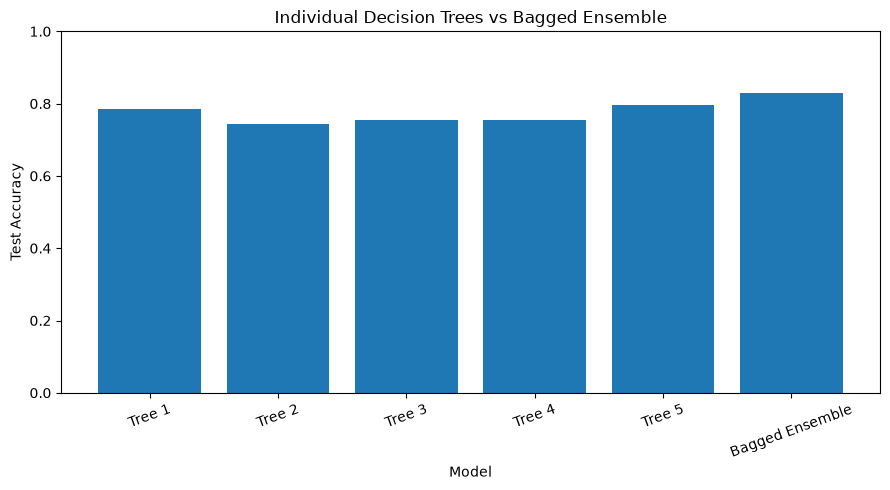

In [ ]:
# Plot individual-tree and ensemble accuracy

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_results["Tree"],
    comparison_results["Test Accuracy"]
)

plt.title("Individual Decision Trees vs Bagged Ensemble")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
#  Configure max_features values for Part B

from sklearn.base import clone
from itertools import combinations

n_encoded_features = (
    len(numeric_features)
    + len(categorical_features)
)

feature_settings = {
    "sqrt": "sqrt",
    "log2": "log2",
    "all": None
}

print("Feature selection settings:")

for setting_name, max_features_value in feature_settings.items():
    print(f"{setting_name}: max_features = {max_features_value}")

print("\nNumber of original numeric features:", len(numeric_features))
print("Number of original categorical features:", len(categorical_features))

Feature selection settings:
sqrt: max_features = sqrt
log2: max_features = log2
all: max_features = None

Number of original numeric features: 23
Number of original categorical features: 7


In [ ]:
# Train five trees for each feature setting

models_by_setting = {}
validation_predictions_by_setting = {}
test_predictions_by_setting = {}

for setting_name, max_features_value in feature_settings.items():

    setting_models = []

    for sample_number, (X_bootstrap, y_bootstrap) in enumerate(
        bootstrap_samples
    ):

        model = Pipeline([
            # Create a fresh preprocessing transformer for every tree
            ("preprocessor", clone(preprocessor)),

            ("tree", DecisionTreeClassifier(
                max_features=max_features_value,
                random_state=RANDOM_STATE + sample_number
            ))
        ])

        model.fit(X_bootstrap, y_bootstrap)
        setting_models.append(model)

    models_by_setting[setting_name] = setting_models

    # Each tree predicts the same validation and test records
    validation_tree_predictions = np.array([
        model.predict(X_validation)
        for model in setting_models
    ])

    test_tree_predictions = np.array([
        model.predict(X_test)
        for model in setting_models
    ])

    validation_predictions_by_setting[setting_name] = (
        validation_tree_predictions
    )

    test_predictions_by_setting[setting_name] = test_tree_predictions

    print(
        f"{setting_name}: trained "
        f"{len(setting_models)} Decision Trees successfully."
    )

print("\nAll feature-randomness models trained successfully.")

sqrt: trained 5 Decision Trees successfully.
log2: trained 5 Decision Trees successfully.
all: trained 5 Decision Trees successfully.

All feature-randomness models trained successfully.


In [ ]:
# Majority voting and validation comparison

def majority_vote(prediction_matrix):
    """
    Combine predictions from multiple trees using majority voting.

    Rows: individual trees
    Columns: employees
    """
    final_predictions = []

    for employee_position in range(prediction_matrix.shape[1]):
        votes = prediction_matrix[:, employee_position]
        vote_counts = Counter(votes)

        final_class = vote_counts.most_common(1)[0][0]
        final_predictions.append(final_class)

    return np.array(final_predictions)


validation_results = []

for setting_name in feature_settings:

    tree_predictions = validation_predictions_by_setting[setting_name]

    ensemble_predictions_for_setting = majority_vote(
        tree_predictions
    )

    validation_accuracy = accuracy_score(
        y_validation,
        ensemble_predictions_for_setting
    )

    validation_results.append({
        "Feature Setting": setting_name,
        "Trees": len(models_by_setting[setting_name]),
        "Validation Accuracy": validation_accuracy
    })

validation_results_df = pd.DataFrame(validation_results)

print("Validation accuracy comparison:")
display(validation_results_df.round(4))

Validation accuracy comparison:


,Feature Setting,Trees,Validation Accuracy
0,sqrt,5,0.8333
1,log2,5,0.8095
2,all,5,0.8401


In [ ]:
# Calculate average pairwise prediction correlation

def average_prediction_correlation(prediction_matrix):
    correlations = []

    for first_tree, second_tree in combinations(
        range(prediction_matrix.shape[0]), 2
    ):
        first_predictions = prediction_matrix[first_tree]
        second_predictions = prediction_matrix[second_tree]

        # Correlation is undefined if either prediction vector is constant
        if (
            np.std(first_predictions) > 0
            and np.std(second_predictions) > 0
        ):
            correlation = np.corrcoef(
                first_predictions,
                second_predictions
            )[0, 1]

            if np.isfinite(correlation):
                correlations.append(correlation)
                                                                                                                                                                                                                                          
    if not correlations:
        return np.nan

    return float(np.mean(correlations))

for row in validation_results:
    setting_name = row["Feature Setting"]

    row["Mean Tree Prediction Correlation"] = (
        average_prediction_correlation(
            validation_predictions_by_setting[setting_name]
        )
    )

validation_results_df = pd.DataFrame(validation_results)

print("Accuracy and diversity comparison:")
display(validation_results_df.round(4))

Accuracy and diversity comparison:


,Feature Setting,Trees,Validation Accuracy,Mean Tree Prediction Correlation
0,sqrt,5,0.8333,0.1593
1,log2,5,0.8095,0.1485
2,all,5,0.8401,0.1550


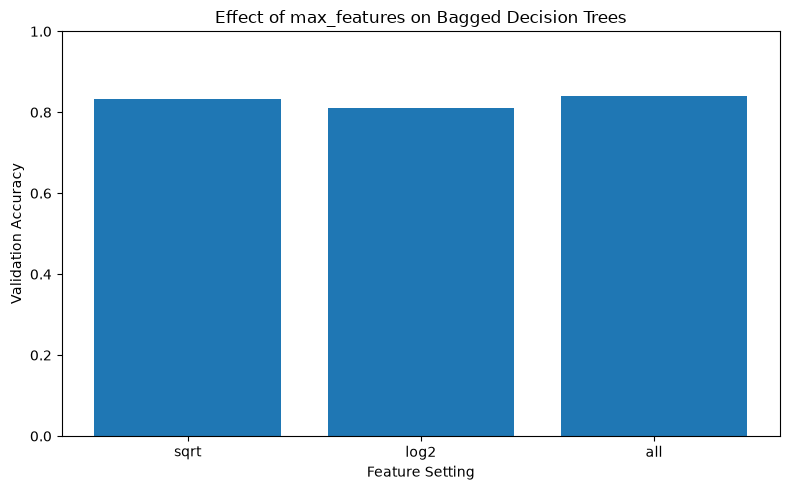

In [ ]:
#  Plot validation accuracy for each feature setting

plt.figure(figsize=(8, 5))

plt.bar(
    validation_results_df["Feature Setting"],
    validation_results_df["Validation Accuracy"]
)

plt.title("Effect of max_features on Bagged Decision Trees")
plt.xlabel("Feature Setting")
plt.ylabel("Validation Accuracy")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [ ]:
# Select the best validation setting and evaluate on test data

best_setting = validation_results_df.loc[
    validation_results_df["Validation Accuracy"].idxmax(),
    "Feature Setting"
]

best_test_predictions = majority_vote(
    test_predictions_by_setting[best_setting]
)

best_test_accuracy = accuracy_score(
    y_test,
    best_test_predictions
)

print("Best setting based on validation accuracy:", best_setting)
print(f"Selected ensemble test accuracy: {best_test_accuracy:.4f}")

print("\nClassification report on the test set:")
print(classification_report(
    y_test,
    best_test_predictions,
    labels=[0, 1],
    target_names=["No Attrition", "Yes Attrition"],
    zero_division=0
))

Best setting based on validation accuracy: all
Selected ensemble test accuracy: 0.8299

Classification report on the test set:
               precision    recall  f1-score   support

 No Attrition       0.88      0.93      0.90       247
Yes Attrition       0.45      0.32      0.38        47

     accuracy                           0.83       294
    macro avg       0.67      0.62      0.64       294
 weighted avg       0.81      0.83      0.82       294



In [ ]:
#Random Forest hyperparameter tuning

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

n_estimators_values = [10, 25, 50, 100]
max_depth_values = [None, 10, 20]
max_features_values = ["sqrt", "log2", None]

rf_results = []
rf_models = {}

for n_trees in n_estimators_values:
    for depth in max_depth_values:
        for feature_setting in max_features_values:

            rf_model = Pipeline([
                ("preprocessor", clone(preprocessor)),
                ("classifier", RandomForestClassifier(
                    n_estimators=n_trees,
                    max_depth=depth,
                    max_features=feature_setting,
                    random_state=RANDOM_STATE,
                    n_jobs=-1
                ))
            ])

            rf_model.fit(X_train, y_train)

            validation_predictions = rf_model.predict(X_validation)
            validation_accuracy = accuracy_score(
                y_validation,
                validation_predictions
            )

            configuration = (
                n_trees,
                depth,
                feature_setting
            )

            rf_models[configuration] = rf_model

            rf_results.append({
                "n_estimators": n_trees,
                "max_depth": depth,
                "max_features": (
                    "all" if feature_setting is None
                    else feature_setting
                ),
                "Validation Accuracy": validation_accuracy
            })

rf_results_df = pd.DataFrame(rf_results)

rf_results_df = rf_results_df.sort_values(
    by="Validation Accuracy",
    ascending=False
).reset_index(drop=True)

display(rf_results_df.head(10).round(4))

,n_estimators,max_depth,max_features,Validation Accuracy
0,100,10.0,all,0.8571
1,100,20.0,all,0.8571
2,25,20.0,log2,0.8571
3,25,NaN,log2,0.8571
4,100,NaN,all,0.8571
5,100,NaN,sqrt,0.8537
6,50,NaN,sqrt,0.8537
7,10,10.0,sqrt,0.8537
8,50,20.0,sqrt,0.8537
9,50,10.0,log2,0.8537


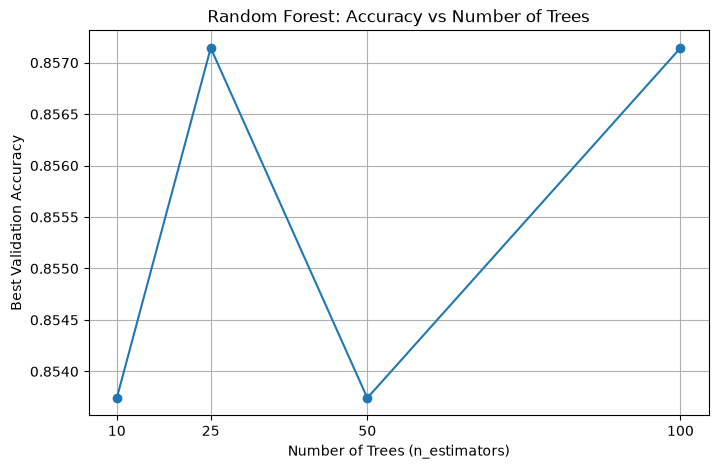

In [ ]:
# Accuracy versus number of trees

best_accuracy_by_tree_count = (
    rf_results_df
    .groupby("n_estimators")["Validation Accuracy"]
    .max()
    .reindex(n_estimators_values)
)

plt.figure(figsize=(8, 5))

plt.plot(
    best_accuracy_by_tree_count.index,
    best_accuracy_by_tree_count.values,
    marker="o"
)

plt.xticks(n_estimators_values)
plt.xlabel("Number of Trees (n_estimators)")
plt.ylabel("Best Validation Accuracy")
plt.title("Random Forest: Accuracy vs Number of Trees")
plt.grid(True)
plt.show()

In [ ]:
# Select the best model using validation accuracy

best_result = rf_results_df.iloc[0]

best_n_estimators = int(best_result["n_estimators"])
best_max_depth = best_result["max_depth"]

best_max_features = best_result["max_features"]

if best_max_features == "all":
    best_max_features = None

best_configuration = (
    best_n_estimators,
    best_max_depth,
    best_max_features
)

best_rf_model = rf_models[best_configuration]

print("Best Random Forest Configuration")
print("--------------------------------")
print("n_estimators:", best_n_estimators)
print("max_depth:", best_max_depth)
print(
    "max_features:",
    "all" if best_max_features is None else best_max_features
)
print(
    "Validation Accuracy:",
    round(best_result["Validation Accuracy"], 4)
)

Best Random Forest Configuration
--------------------------------
n_estimators: 100
max_depth: 10.0
max_features: all
Validation Accuracy: 0.8571


In [ ]:
# Final test evaluation

test_predictions = best_rf_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Test Accuracy: {test_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["No Attrition", "Yes Attrition"],
    zero_division=0
))

Test Accuracy: 0.8503

Classification Report:
               precision    recall  f1-score   support

 No Attrition       0.87      0.97      0.92       247
Yes Attrition       0.58      0.23      0.33        47

     accuracy                           0.85       294
    macro avg       0.72      0.60      0.62       294
 weighted avg       0.82      0.85      0.82       294



Top 10 Employee Attrition Predictors:


,Original Feature,Importance
0,MonthlyIncome,0.1102
1,Age,0.0839
2,DailyRate,0.0590
3,TotalWorkingYears,0.0585
4,HourlyRate,0.0529
5,MonthlyRate,0.0474
6,DistanceFromHome,0.0382
7,OverTime_No,0.0371
8,YearsWithCurrManager,0.0347
9,EnvironmentSatisfaction,0.0323


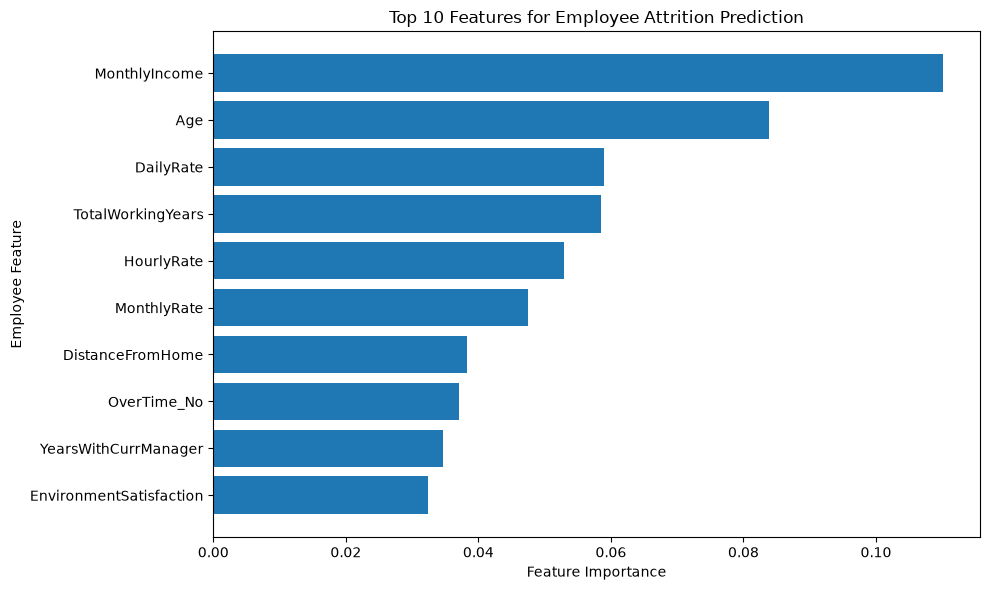

In [ ]:
#  Feature importance

fitted_preprocessor = best_rf_model.named_steps["preprocessor"]
fitted_forest = best_rf_model.named_steps["classifier"]

encoded_feature_names = fitted_preprocessor.get_feature_names_out()
encoded_importances = fitted_forest.feature_importances_

importance_df = pd.DataFrame({
    "Encoded Feature": encoded_feature_names,
    "Importance": encoded_importances
})

# Remove preprocessing prefixes, such as numeric__ and categorical__
importance_df["Original Feature"] = (
    importance_df["Encoded Feature"]
    .str.replace(r"^(numeric|categorical)__", "", regex=True)
)

# Combine importance values for encoded categories of the same original feature
original_importance_df = (
    importance_df
    .groupby("Original Feature", as_index=False)["Importance"]
    .sum()
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

top_10_features = original_importance_df.head(10)

print("Top 10 Employee Attrition Predictors:")
display(top_10_features.round(4))

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_features["Original Feature"][::-1],
    top_10_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Employee Feature")
plt.title("Top 10 Features for Employee Attrition Prediction")
plt.tight_layout()
plt.show()

In [ ]:
# Top 10 encoded features

top_encoded_features = (
    importance_df
    .sort_values("Importance", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(top_encoded_features.round(4))

,Encoded Feature,Importance,Original Feature
0,numeric__MonthlyIncome,0.1102,MonthlyIncome
1,numeric__Age,0.0839,Age
2,numeric__DailyRate,0.0590,DailyRate
3,numeric__TotalWorkingYears,0.0585,TotalWorkingYears
4,numeric__HourlyRate,0.0529,HourlyRate
5,numeric__MonthlyRate,0.0474,MonthlyRate
6,numeric__DistanceFromHome,0.0382,DistanceFromHome
7,categorical__OverTime_No,0.0371,OverTime_No
8,numeric__YearsWithCurrManager,0.0347,YearsWithCurrManager
9,numeric__EnvironmentSatisfaction,0.0323,EnvironmentSatisfaction


In [ ]:
# Report-ready feature importance summary

print("Top 10 Features Associated with Predicted Attrition")
print("---------------------------------------------------")

for rank, row in enumerate(
    top_10_features.itertuples(index=False),
    start=1
):
    print(
        f"{rank}. {row[0]}: "
        f"{row[1]:.4f}"
    )

Top 10 Features Associated with Predicted Attrition
---------------------------------------------------
1. MonthlyIncome: 0.1102
2. Age: 0.0839
3. DailyRate: 0.0590
4. TotalWorkingYears: 0.0585
5. HourlyRate: 0.0529
6. MonthlyRate: 0.0474
7. DistanceFromHome: 0.0382
8. OverTime_No: 0.0371
9. YearsWithCurrManager: 0.0347
10. EnvironmentSatisfaction: 0.0323
